In [2]:
!pip install -q ultralytics split-folders kagglehub matplotlib

In [3]:
import kagglehub
import os
import splitfolders

# Descargar el dataset oficial de Daniel Rey directamente en Colab
dataset_raw_path = kagglehub.dataset_download("danielrey96/colombian-sign-language-lsc-alphabet")
print("Dataset descargado en:", dataset_raw_path)

100%|██████████| 27.6M/27.6M [00:00<00:00, 59.7MB/s]

Extracting files...


Dataset descargado en: /root/.cache/kagglehub/datasets/danielrey96/colombian-sign-language-lsc-alphabet/versions/1


In [4]:
# Carpeta de salida formateada para YOLO
yolo_dataset_path = "./dataset_lsc_yolo"

# Dividir 80% train / 20% val de forma automática
splitfolders.ratio(
    dataset_raw_path,
    output=yolo_dataset_path,
    seed=42,
    ratio=(0.8, 0.2),
    group_prefix=None
)

print("Dataset organizado exitosamente.")

Copying files: 0 files [00:00, ? files/s]

Dataset organizado exitosamente.


In [5]:
import os
import shutil
import splitfolders

# 1. Buscar automáticamente la subcarpeta real que contiene las carpetas de las letras
real_data_dir = dataset_raw_path
for root, dirs, files in os.walk(dataset_raw_path):
    if len(dirs) >= 10:  # Detecta la carpeta que contiene las carpetas por letra
        real_data_dir = root
        break

print("Carpeta real de las imágenes encontrada en:", real_data_dir)

# 2. Limpiar cualquier intento previo incompleto
if os.path.exists("./dataset_lsc_yolo"):
    shutil.rmtree("./dataset_lsc_yolo")

# 3. Dividir de forma correcta (80% train / 20% val)
splitfolders.ratio(
    real_data_dir,
    output="./dataset_lsc_yolo",
    seed=42,
    ratio=(0.8, 0.2),
    group_prefix=None
)

# 4. Verificación de seguridad
train_classes = os.listdir("./dataset_lsc_yolo/train")
print(f"✅ ¡Solucionado! Se encontraron {len(train_classes)} carpetas de letras en train:")
print(train_classes)

Carpeta real de las imágenes encontrada en: /root/.cache/kagglehub/datasets/danielrey96/colombian-sign-language-lsc-alphabet/versions/1/Todas


Copying files: 5439 files [00:01, 4683.39 files/s]

✅ ¡Solucionado! Se encontraron 22 carpetas de letras en train:
['Y', 'N', 'X', 'F', 'T', 'O', 'K', 'R', 'D', 'L', 'I', 'P', 'H', 'B', 'E', 'C', 'Q', 'A', 'V', 'M', 'W', 'U']


In [6]:
from ultralytics import YOLO

# Cargar el modelo base y entrenar
model = YOLO("yolov8n-cls.pt")

results = model.train(
    data="./dataset_lsc_yolo",
    epochs=15,
    imgsz=250,
    batch=32,
    name="lsc_colab_run"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./dataset_lsc_yolo, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None,

📁 Mostrando resultados desde: /content/runs/classify/lsc_colab_run

📊 Archivo: confusion_matrix.png


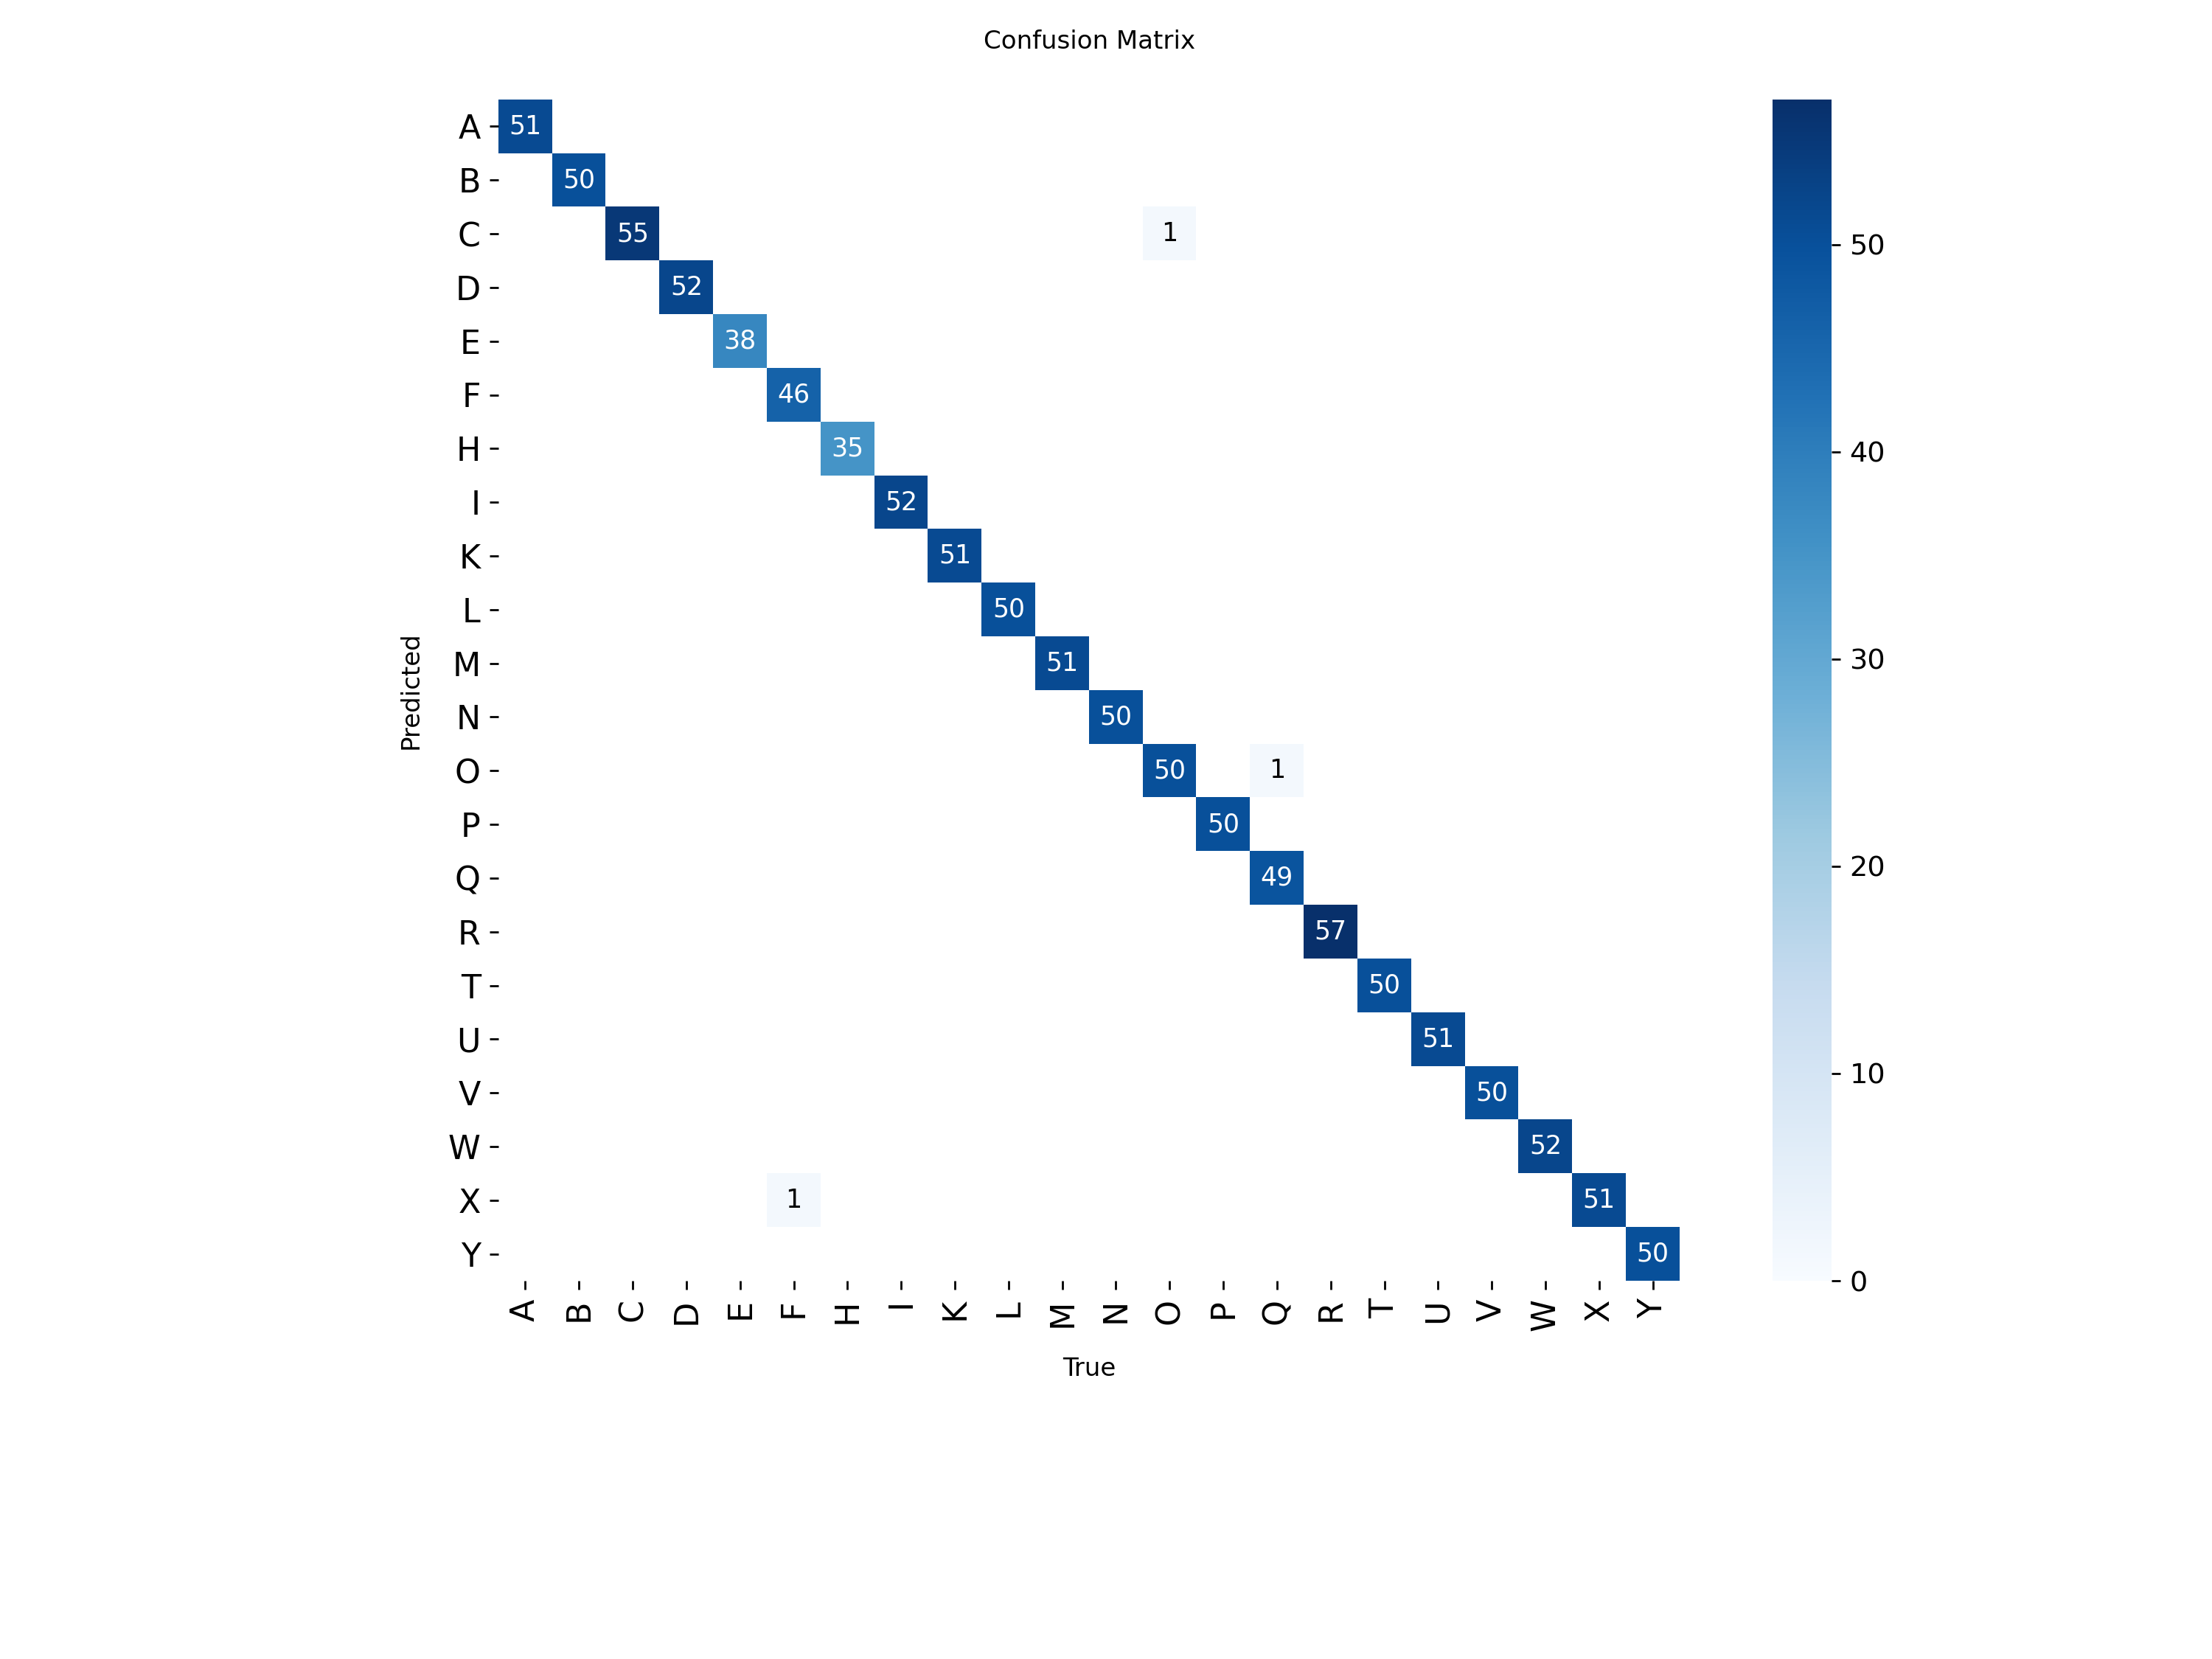

📊 Archivo: confusion_matrix_normalized.png


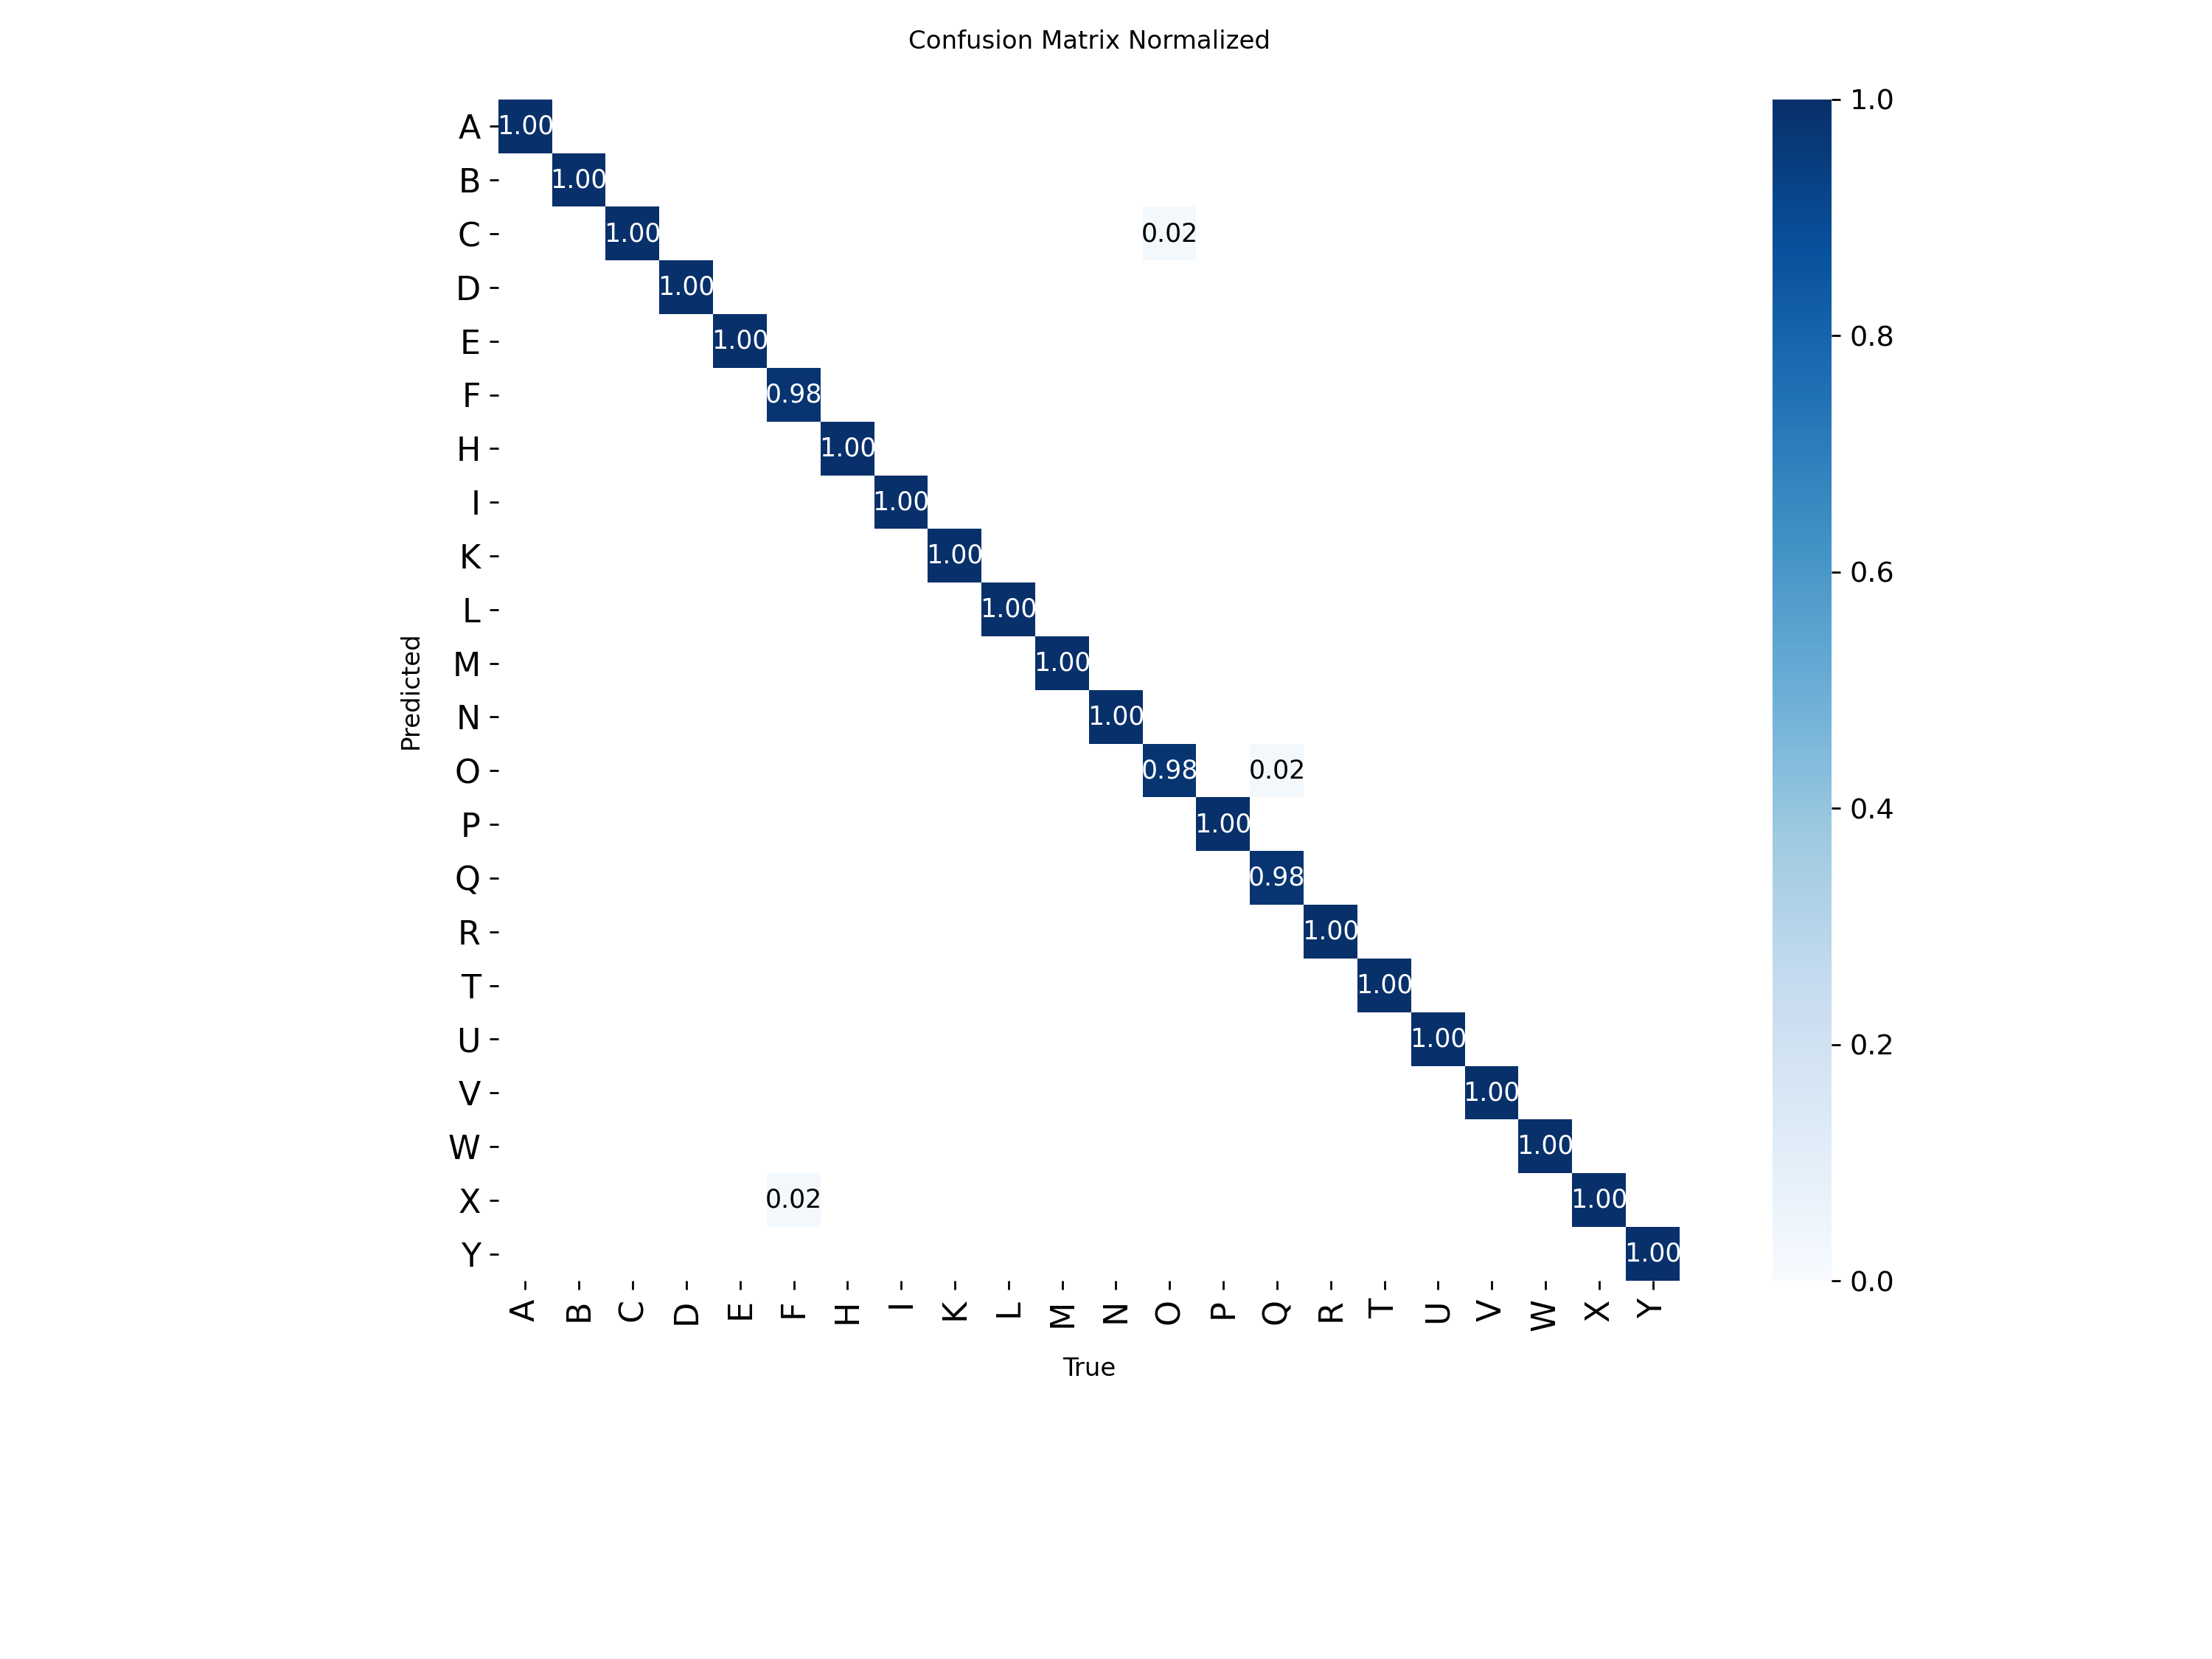

📊 Archivo: results.png


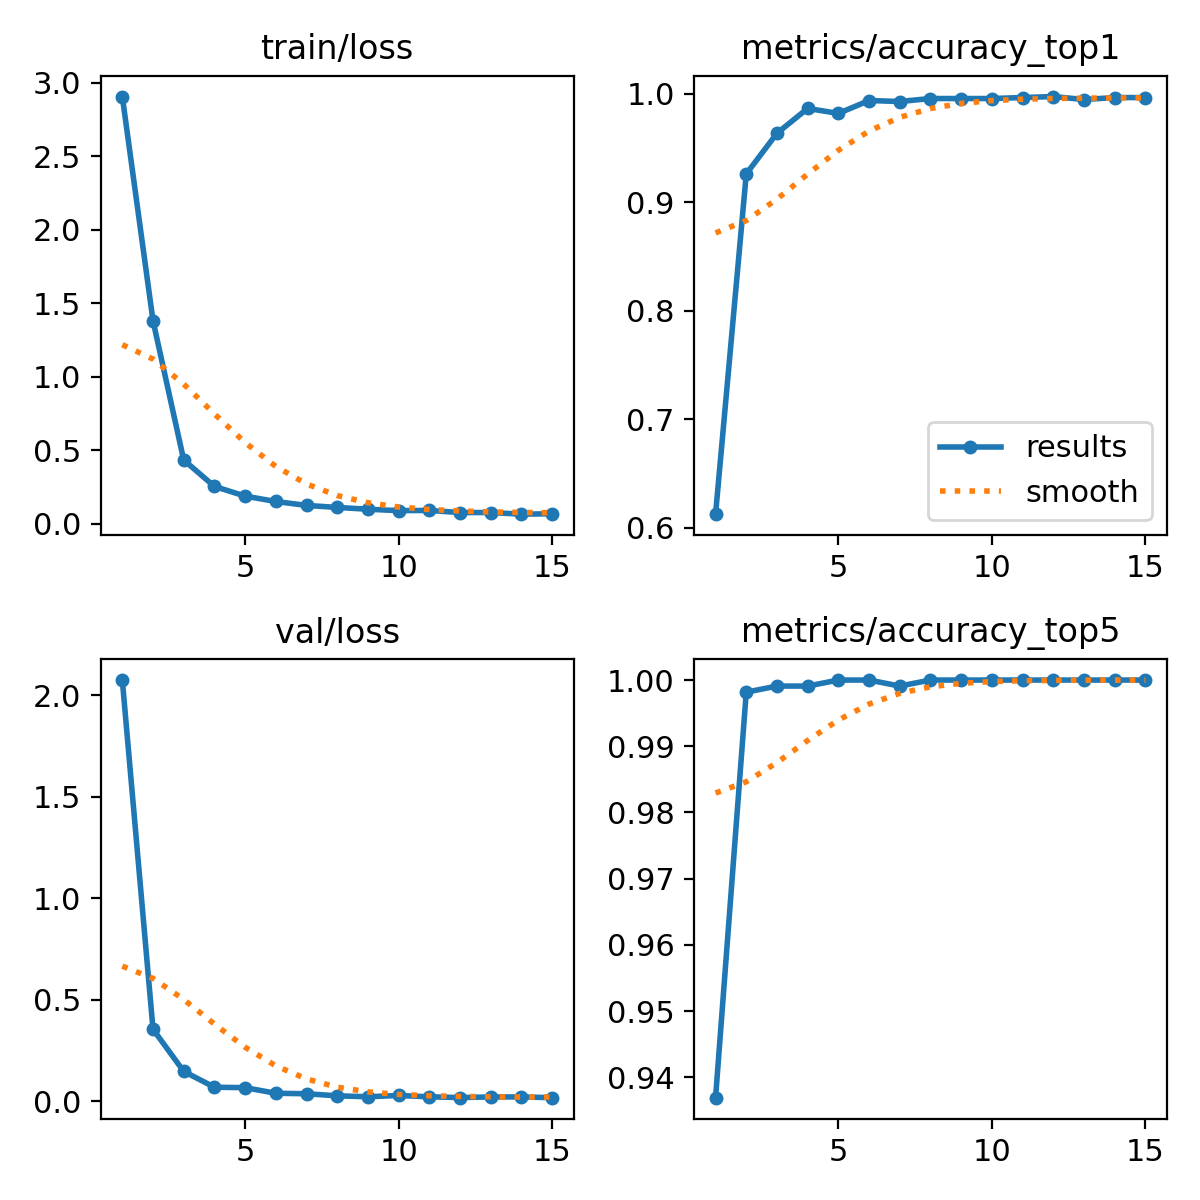

In [7]:
import os
import glob
from IPython.display import Image, display

# 1. Obtener automáticamente la ruta exacta donde YOLO guardó los resultados
save_dir = str(model.trainer.save_dir)
print(f"📁 Mostrando resultados desde: {save_dir}\n")

# 2. Buscar todas las imágenes PNG generadas (Matriz de confusión, gráficas de loss/accuracy, etc.)
png_files = glob.glob(os.path.join(save_dir, "*.png"))

if png_files:
    for filepath in sorted(png_files):
        # Filtrar para mostrar principalmente las gráficas clave del informe
        filename = os.path.basename(filepath)
        if any(keyword in filename for keyword in ["confusion", "results", "val_batch"]):
            print(f"📊 Archivo: {filename}")
            display(Image(filename=filepath))
else:
    print("⚠️ No se encontraron gráficas en la carpeta de salida.")

In [8]:
import os
import glob
from google.colab import files

# 1. Intentar obtener la ruta directa desde el objeto del entrenamiento activo
best_weights_path = ""

if hasattr(model, 'trainer') and model.trainer is not None:
    best_weights_path = os.path.join(str(model.trainer.save_dir), "weights", "best.pt")

# 2. Si no se detecta por memoria, buscar el archivo best.pt más reciente en el disco
if not os.path.exists(best_weights_path):
    pt_files = glob.glob("runs/classify/*/weights/best.pt") + glob.glob("runs/segment/*/weights/best.pt") + glob.glob("runs/detect/*/weights/best.pt")
    if pt_files:
        best_weights_path = max(pt_files, key=os.path.getmtime)

# 3. Iniciar la descarga del archivo encontrado
if os.path.exists(best_weights_path):
    print(f"✅ ¡Archivo encontrado! Descargando desde: {best_weights_path}")
    files.download(best_weights_path)
else:
    print("⚠️ No se encontró ningún archivo best.pt. Asegúrate de ejecutar primero la celda del Paso 4 (Entrenamiento).")

✅ ¡Archivo encontrado! Descargando desde: /content/runs/classify/lsc_colab_run/weights/best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>